In [13]:
#Dataset Loading, Train/Test Split, and Standard Scaling
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
#Boxplot and Scatter Plot Visualization Function
import matplotlib.pyplot as plt
import seaborn as sns
def plot_outliers_and_distribution(df, column_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.boxplot(y=df[column_name], ax=axes[0])
    axes[0].set_title(f"Boxplot of {column_name}")

    sns.scatterplot(x=df.index, y=df[column_name], ax=axes[1])
    axes[1].set_title(f"Scatter Plot of {column_name}")
    axes[1].set_xlabel("Index")
    plt.tight_layout()
    plt.show()

In [1]:
#Linear Regression with RMSE, MAE, and $R^2$ Score
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
housing = fetch_california_housing(as_frame=True)
X, y = housing.data, housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

MAE: 0.5332
RMSE: 0.7456
R² Score: 0.5758


In [2]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42
)
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Predicted Classes:", predictions)

Predicted Classes: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


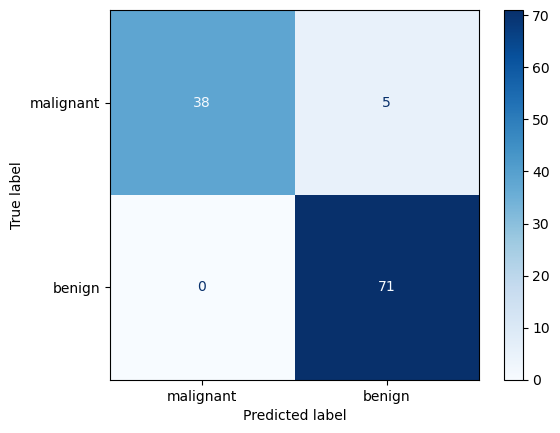

In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42
)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=data.target_names
)
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [8]:
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
X, y = make_classification(
    n_samples=1000, n_features=10, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_acc = accuracy_score(y_test, dt.predict(X_test))

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test))

print(f"Decision Tree Accuracy: {dt_acc:.4f}")
print(f"Random Forest Accuracy: {rf_acc:.4f}")

if rf_acc > dt_acc:
    print("Random Forest performed better.")
elif dt_acc > rf_acc:
    print("Decision Tree performed better.")
else:
    print("Both models performed equally.")

Decision Tree Accuracy: 0.8633
Random Forest Accuracy: 0.8867
Random Forest performed better.


In [9]:
from sklearn.metrics import f1_score, precision_score, recall_score

y_true = [0, 1, 1, 0, 1, 2, 1, 2, 0, 1]
y_pred = [0, 1, 0, 0, 1, 2, 1, 1, 0, 1]

target_class = 1

precision = precision_score(y_true, y_pred, pos_label=target_class, average=None)[target_class]
recall = recall_score(y_true, y_pred, pos_label=target_class, average=None)[target_class]
f1 = f1_score(y_true, y_pred, pos_label=target_class, average=None)[target_class]

print(f"Metrics for Target Class {target_class}:")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Metrics for Target Class 1:
Precision: 0.8000
Recall:    0.8000
F1-Score:  0.8000


In [10]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score

X, y = make_regression(n_samples=500, n_features=15, noise=0.1, random_state=42)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
ridge = Ridge(alpha=1.0)
scores = cross_val_score(ridge, X, y, cv=kf, scoring="r2")

print(f"5-Fold R² Scores: {scores}")
print(f"Mean R² Score: {np.mean(scores):.4f}")
print(f"Standard Deviation (Stability): {np.std(scores):.4f}")

5-Fold R² Scores: [0.99999139 0.99999113 0.99999181 0.99999092 0.99999211]
Mean R² Score: 1.0000
Standard Deviation (Stability): 0.0000


In [11]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

X, y = load_breast_cancer(return_X_y=True)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20],
}
rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=rf, param_grid=param_grid, cv=5, scoring="accuracy"
)
grid_search.fit(X, y)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best Accuracy: {grid_search.best_score_:.4f}")

Best Hyperparameters: {'max_depth': None, 'n_estimators': 200}
Best Accuracy: 0.9578


In [12]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
pipeline = Pipeline(
    [
        ("scaler", MinMaxScaler()),
        ("classifier", LogisticRegression(max_iter=200)),
    ]
)
pipeline.fit(X_train, y_train)

test_score = pipeline.score(X_test, y_test)
print(f"Pipeline Test Accuracy: {test_score:.4f}")

Pipeline Test Accuracy: 0.9825
